# Projeto de Fusão de Informação em Análises de Dados

<div style="width: 100%; overflow: hidden;">

    <a href="http://www.uc.pt/fctuc/dei/">

    <div style="display: block;margin-left: auto;margin-right: auto; width: 100%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>

    </a>

</div>

---
**Afonso Rodrigues -- 2020242400**

**Emanuel Pacheco -- 2024138898**

---

## 1. Introduction

In this project, we aim to apply two variations of the Kalman Filter discussed in class—the Extended Kalman Filter (EKF) and the Unscented Kalman Filter (UKF)—to estimate a robot's movement. We will compare their performance with both the robot's true trajectory and its trajectory affected by sensor noise. Additionally, we will evaluate these filters against other localization methods, such as dead reckoning, to assess their effectiveness in improving position estimation accuracy.

## 2. Libraries used

In [40]:
import numpy as np
import math
import matplotlib.pyplot as plt
import scipy.linalg
from IPython.display import display, clear_output
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


np.random.seed(42)

## 3. Motion Model, Observation Model, and Input Calculations

In this chapter, we will define the key components required for the implementation of the Kalman filters: the motion model, the observation model, the input calculation, and the observation function. 

These components are essential for simulating the robot's movement and for applying the Extended Kalman Filter (EKF) and Unscented Kalman Filter (UKF).

### 3.1. Input Calculations
The input vector​ is calculated based on the robot's velocity​ and angular velocity​, which are obtained from the robot's speed sensor and gyroscope, respectively.

In [41]:
def calc_input():
    v = 1.0  # [m/s]
    yawrate = 0.1  # [rad/s]
    u = np.array([[v, yawrate]]).T # Control input vector (velocity and yaw rate)
    return u

### 3.2. Motion Model
The motion model describes how the robot's state evolves over time based on its current state and control inputs.

In [42]:
def motion_model(x, u, dt):
    yaw = x[2, 0]  # Current yaw

    A = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0],
                  [0, 0, 1, 0],
                  [0, 0, 0, 0]])

    # Control input matrix: Maps control input (velocity and yaw rate) to state changes
    B = np.array([[np.cos(yaw) * dt, 0], # Position x changes depending on yaw and velocity
                  [np.sin(yaw) * dt, 0], # Position y changes depending on yaw and velocity
                  [0, dt],               # Yaw changes depending on yaw rate
                  [1, 0]])               # Velocity does not change

    # State update: Predicts the next state using the system dynamics
    x = A.dot(x) + B.dot(u)

    return x

### 3.3. Observation Function

The observation function simulates the data obtained from the GNSS sensor. It takes the robot's true state​ and adds noise to simulate real-world sensor inaccuracies.

In [43]:
def observation(xTrue, xd, u, GPS_Noise, Input_Noise, dt):
    # Update true state using the motion model
    xTrue = motion_model(xTrue, u, dt)

    # Add noise to GPS x-y
    zx = xTrue[0, 0] + np.random.randn() * GPS_Noise[0, 0]
    zy = xTrue[1, 0] + np.random.randn() * GPS_Noise[1, 1]
    z = np.array([[zx, zy]])

    # Add noise to input
    ud1 = u[0, 0] + np.random.randn() * Input_Noise[0, 0]
    ud2 = u[1, 0] + np.random.randn() * Input_Noise[1, 1]
    ud = np.array([[ud1, ud2]]).T

    # Update estimated state using the noisy control input
    xd = motion_model(xd, ud, dt)

    return xTrue, z, xd, ud

### 3.4. Observation Model

The observation model describes how the robot's state is measured by its sensors. In this project, the robot uses a GNSS sensor to measure its xx-yy position. 

In [44]:
def observation_model(x):
    # Observation matrix (maps state to measurement)
    C = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0]])

    z = C.dot(x)

    return z

##  4. Extended Kalman Filter (EKF)

The EKF is a variation of the Kalman Filter that is used to calculate the next state in a dynamic system in **slightly nonlinear systems** from noisy measurements. In its nature its a recursive method that predicts the next state based on the current state and the system dynamics, using a nonlinear function and then updates this prediction using the new measurement, again applying a nonlinear measurement function.

It uses **Jacobian Derivatives** to linearize non-linear functions, which form a Jacobian Matrix. 

Although a bit more computationally expensive than the regular Kalman Filter, its price computationally comes from the fact that there is a need to calculate said Jacobian Derivatives.

### 4.1. Jacobian of the Motion Model

The Jacobian of the motion model (denoted as jacobF) describes how the robot's state evolves over time. 

It is a matrix of partial derivatives of the state transition function with respect to the state variables.

In [45]:
def jacobF(x, u, dt):
    v = u[0, 0] 
    yaw = x[2, 0]

    # Jacobian of Motion Model
    jF = np.array([[1, 0, -v * np.sin(yaw) * dt, np.cos(yaw) * dt],
                   [0, 1,  v * np.cos(yaw) * dt, np.sin(yaw) * dt],
                   [0, 0, 1, 0],
                   [0, 0, 0, 1]])

    return jF

### 4.2. Jacobian of the Observation Model
The Jacobian of the observation model (denoted as jacobH) describes how the sensor measurements depend on the state variables.

It is a matrix of partial derivatives of the observation function with respect to the state variables.

In [46]:
def jacobH():
    # Jacobian of Observation Model
    jH = np.array([[1, 0, 0, 0],
                   [0, 1, 0, 0]])	

    return jH

### 4.3. Extended Kalman Filter (EKF) Implementation

The EKF consists of two main steps: Prediction and Update

#### 4.3.1 Prediction Steps
1. **State Extrapolation**: The predicted state is calculated using the motion model. This basically predicts where the robot will be based on the input and current state.
2. **Covariance Extrapolation**: The predicted covariance is calculated using the Jacobian of the motion model. This basically predicts the uncertainty in the state estimate after the motion.

#### 4.3.2. Update Steps
1. **Kalman Gain Calculation**: The Kalman Gain is calculated using the Jacobian of the observation model. The Kalman Gain determines how much weight to give to the sensor measurement versus the predicted state.
2. **State Update**: The state estimate is updated using the sensor measurement. This step corrects the predicted state using the sensor data.
3. **Covariance Update**: The covariance estimate is updated. This step reduces the uncertainty in the state estimate after incorporating the sensor measurement.


In [47]:
def ekf_estimation(xEst, PEst, z, u, Q, R, dt):
    # Predict
    # State Extrapolation
    xPred = motion_model(xEst, u, dt)
    
    # Covariance Extrapolation
    jF = jacobF(xEst, u, dt)
    PPred = jF.dot(PEst).dot(jF.T) + Q
    

    # Update
    # Kalman Gain
    jH = jacobH()
    K = PPred.dot(jH.T).dot(np.linalg.inv(jH.dot(PPred).dot(jH.T) + R))

    # State Update
    xEst = xPred + K.dot(z.T - observation_model(xPred))

    # Covariance Update
    PEst = (np.eye(len(xEst)) - K.dot(jH)).dot(PPred)
    
    return xEst, PEst

## 5. Unscented Kalman Filter (UKF)

The UKF is another extension of the Kalman Filter that handles **highly nonlinear systems** well by sampling sigma points in order to approximate the distribution of the state, in contrast with EKF that can't function well if there are non-derivative points.

It can be even more computationally expensive than EKF, due the need to propagate multiple sigma points as well as tuning them, although higher computational cost.

### 5.1. Setting Up the UKF Parameters

This cell of code sets up the Unscented Kalman Filter (UKF) by calculating the lambda parameter, weights for the mean and covariance, and the gamma scaling factor, which are essential for the sigma point generation and state estimation in the UKF algorithm. The weights and gamma are derived based on the input parameters nx, ALPHA, BETA, and KAPPA.

In [48]:
def setup_ukf(nx, ALPHA, BETA, KAPPA):
    # calculate lambda
    lamb = ALPHA ** 2 * (nx + KAPPA) - nx

    # calculate the weights
    # w^(0)
    wm = [lamb / (lamb + nx)] # wm corresponds to w of the UKF Algorithm
    # wc^(0)
    wc = [(lamb / (lamb + nx)) + (1 - ALPHA ** 2 + BETA)]
    for _ in range(2 * nx):
        # w^(+-i)
        wm.append(1.0 / (2 * (nx + lamb)))
        # wc^(+-i)
        wc.append(1.0 / (2 * (nx + lamb)))
    
    # define gamma
    gamma = math.sqrt(nx + lamb)

    wm = np.array([wm])
    wc = np.array([wc])

    return wm, wc, gamma

### 5.2. Sigma Point Generation and Propagation

Instead of linearizing the motion model (as in the EKF), the UKF generates a set of sigma points around the current state estimate. 

These sigma points are chosen to capture the mean and covariance of the state distribution.
The sigma points are propagated through the nonlinear motion model to predict the state distribution.

In [49]:
def generate_sigma_points(xEst, PEst, gamma):
    # The first sigma point is the current state estimate (mean).
    x_0 = xEst

	# Generate sigma points by adding and subtracting a scaled version of the
    # square root of the covariance matrix from the state estimate.
    # This ensures the sigma points capture the spread of the distribution.
    sigma_neg = xEst + gamma * scipy.linalg.sqrtm(PEst)
    sigma_pos = xEst - gamma * scipy.linalg.sqrtm(PEst)	

	# Combine the sigma points into a single matrix.
    sigma = np.concatenate((x_0, sigma_neg, sigma_pos), axis=1)

    return sigma

In [50]:
# Predicts the future state of the sigma points using a motion model (motion_model), which incorporates the control input (u) and time step (dt)
def predict_sigma_motion(sigma, u, dt):
    # Sigma Points prediction with motion model
    sigma = motion_model(sigma, u, dt)
    return sigma

In [51]:
# Predicts the expected observations for the sigma points using an observation model 
def predict_sigma_observation(sigma):
    # Sigma Points prediction with observation model
    sigma = observation_model(sigma)
    return sigma

### 5.3. Covariance and Cross-Covariance Calculations

The predicted covariance is calculated using the weighted outer product of the propagated sigma points. This captures the uncertainty in the state estimate after the motion.

In [52]:
# Computes the state covariance matrix using the sigma points, the state estimate, the weights, and an optional process noise covariance matrix
def calc_sigma_covariance(x, sigma, wc, Pi):
    # Calculates the covariance matrix using sigma points and weights.
    P = (wc * (sigma - x)).dot((sigma - x).T) + Pi

    return P

In [53]:
# Computes the cross-covariance matrix between the state sigma points and the predicted observation sigma points
def calc_pxz(sigma, x, z_sigma, zb, wc):
    # Calculates the cross-covariance matrix using sigma points and weights.
    P = (wc * (sigma - x)).dot((z_sigma - zb).T)
    return P

### 5.4. Unscented Kalman Filter (UKF) Implementation

The UKF consists of two main steps: Prediction and Update. Unlike the EKF, the UKF uses sigma points to approximate the nonlinear transformations of the state and measurement distributions, avoiding the need for Jacobian matrices.

#### 5.4.1. Predictions Steps

**1. Measurement Sigma Points:** The sigma points are transformed through the nonlinear observation model to predict the sensor measurements.

**2. Predicted Measurement:** The predicted measurement is computed as the weighted average of the transformed sigma points.

#### 5.4.2. Update Steps

**1. Kalman Gain Calculation:** The Kalman Gain is calculated using the cross-covariance between the state and measurement sigma points, as well as the innovation covariance (uncertainty in the predicted measurement). The Kalman Gain determines how much weight to give to the sensor measurement versus the predicted state.

**2. State Update:** The state estimate is updated by combining the predicted state with the difference between the actual sensor measurement and the predicted measurement, weighted by the Kalman Gain.
   
**3. Covariance Update:** The covariance estimate is updated to reflect the reduced uncertainty in the state estimate after incorporating the sensor measurement.

In [54]:
def ukf_estimation(xEst, PEst, z, u, wm, wc, gamma, Q, R, dt):
    # ==============================
    # Predict (UKF - Time Update)
    # ==============================
    
    # Generate sigma points using the current state estimate (xEst) and covariance (PEst).
    sigma = generate_sigma_points(xEst, PEst, gamma)
    
    # Propagate the sigma points through the motion model to predict the next state.
    sigma = predict_sigma_motion(sigma, u, dt)

    # Calculate the predicted state mean (xPred) using the propagated sigma points and weights (wm).
    xPred = wm.dot(sigma.T).T

    # Calculate the predicted covariance (PPred) using the predicted state mean (xPred),
    # the propagated sigma points, weights (wc), and process noise covariance (Q).
    PPred = calc_sigma_covariance(xPred, sigma, wc, Q)
    

    # ==============================
    # Update (UKF - Measurement Update)
    # ==============================
    
    # Calculate the predicted measurement (zPred) using the predicted state mean (xPred).
    zPred = observation_model(xPred)
    
    # Calculate the measurement residual (y) by comparing the actual measurement (z)
    # with the predicted measurement (zPred).
    y = z.T - zPred
    
    # Generate sigma points for the measurement update using the predicted state mean (xPred)
    # and predicted covariance (PPred).
    z_sigma = generate_sigma_points(xPred, PPred, gamma)

    # Propagate the measurement sigma points through the observation model.
    z_sigma = predict_sigma_observation(z_sigma)

    # Calculate the predicted measurement mean (zb) using the propagated measurement sigma points
    # and weights (wm).
    zb = wm.dot(z_sigma.T).T
    
    # Calculate the innovation covariance (Pz) using the predicted measurement mean (zb),
    # the propagated measurement sigma points, weights (wc), and measurement noise covariance (R).
    Pz = calc_sigma_covariance(zb, z_sigma, wc, R)
    
    # Calculate the cross-covariance matrix (Pxz) between the state and measurement sigma points.
    Pxz = calc_pxz(sigma, xPred, z_sigma, zb, wc)
    
    # Calculate the Kalman gain (K) using the cross-covariance matrix (Pxz)
    # and the innovation covariance (Pz).
    K = Pxz.dot(scipy.linalg.inv(Pz))
    
    # Update the state estimate (xEst) using the predicted state mean (xPred),
    # the Kalman gain (K), and the measurement residual (y).
    xEst = xPred + K.dot(y)
    
    # Update the covariance estimate (PEst) using the predicted covariance (PPred),
    # the Kalman gain (K), and the innovation covariance (Pz).
    PEst = PPred - K.dot(Pz).dot(K.T)
    
    return xEst, PEst

## 6. Main Function Implementation

## 6.1. Estimation Parameters for EKF and UKF

The following cell defines the noise parameters and UKF tuning parameters for the simulation:


**Process Noise Estimation (Q)**: Represents the uncertainty in the system dynamics, with values for position, angle, and velocity.

**Measurement Noise Covariance (R)**: represents the uncertainty in sensor measurements, with values for position.

**GPS Noise:** This represents the noise covariance matrix for GPS measurements.

**Input Noise:** This represents the noise covariance matrix for the control inputs


These parameters are specific to the Unscented Kalman Filter (UKF) and control how the sigma points are generated 
and weighted:
- **ALPHA:** determines the spread of the sigma points around the mean;
- **BETA:** incorporates prior knowledge of the distribution of the state;
- **KAPPA:** secondary scaling parameter that is usually set to 0.

In [55]:
Q = np.diag([0.3, 0.3, np.deg2rad(1.0), 1.0]) ** 2 
R = np.diag([0.6, 0.6]) ** 2 

GPS_Noise = np.diag([0.5, 0.5])**2
Input_Noise = np.diag([1.0, np.deg2rad(30.0)])**2

ALPHA = 0.001 # Low value means the sigma points are close to the mean
BETA = 2 # 2 is optimal for Gaussian distributions
KAPPA = -1 # Set to 0 for state estimation problems.

dt = 0.1  # time tick [s]
SIM_TIME = 50.0 # finish simulation

### 6.2. Covariance Ellipse

This function plots a covariance ellipse to visualize the uncertainty in the state estimate. It extracts the position covariance (Pxy), computes its eigenvalues and eigenvectors to determine the ellipse's orientation and size, and then plots the ellipse centered at the estimated state (xEst). The ellipse's shape and angle represent the uncertainty and correlation in the position estimates.

In [56]:
def plot_covariance_ellipse(xEst, PEst, color):
    Pxy = PEst[0:2, 0:2]
    eigval, eigvec = np.linalg.eig(Pxy)

    if eigval[0] >= eigval[1]:
        bigind = 0
        smallind = 1
    else:
        bigind = 1
        smallind = 0

    t = np.arange(0, 2 * math.pi + 0.1, 0.1)
    a = math.sqrt(eigval[bigind])
    b = math.sqrt(eigval[smallind])
    x = [a * math.cos(it) for it in t]
    y = [b * math.sin(it) for it in t]
    angle = math.atan2(eigvec[bigind, 1], eigvec[bigind, 0])
    R = np.array([[math.cos(angle), math.sin(angle)],
                  [-math.sin(angle), math.cos(angle)]])
    fx = R.dot(np.array([[x, y]]))
    px = np.array(fx[0, :] + xEst[0, 0]).flatten()
    py = np.array(fx[1, :] + xEst[1, 0]).flatten()
    plt.plot(px, py, color)

## 6.3. Performance Metrics

This function calculates performance metrics to evaluate the accuracy of the predicted states compared to the true states

**MAE (Mean Absolute Error)**: Measures the average absolute difference between true and predicted states.

**RMSE (Root Mean Squared Error)**: Measures the square root of the average squared differences, giving more weight to larger errors.

**MAPE (Mean Absolute Percentage Error)**: Measures the average percentage error, with a small constant added to avoid division by zero.

**R² (R-squared)**: Measures how well the predicted states explain the variance in the true states, ranging from 0 to 1.

In [57]:
def calculate_metrics(true_states, predicted_states):
	mae = mean_absolute_error(true_states, predicted_states)
	rmse = np.sqrt(mean_squared_error(true_states, predicted_states))
 
	# mape tends to have a division by zero error, so we need to handle it separately
	# we handle it by issuing when a true value is 0, we set it as "epsilon = 1e-10"
	epsilon = 1e-10  # Small constant to avoid division by zero
	mape = np.mean(np.abs((true_states - predicted_states) / (true_states + epsilon))) * 100
	r2 = r2_score(true_states, predicted_states)
	return mae, rmse, mape, r2

## 6.4. Main Function Implementation

The following cell defines the main function, which shows the simulation of the robot's motion and state estimation using Dead-Reckoning, EKF, and UKF. It initializes the state vectors, simulates the robot's movement, performs state estimation, and visualizes the results in an animated graph if show_animation is enabled. After the simulation, it calculates and prints performance metrics (MAE, RMSE, MAPE, R²) for each method.

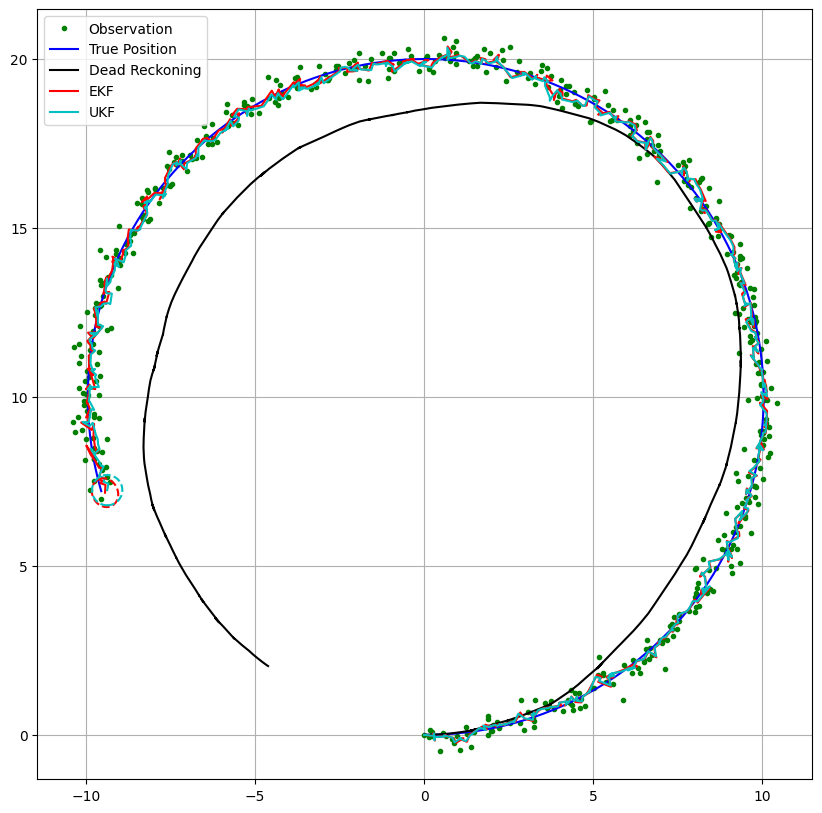

Dead-Reckoning:
MAE = 1.98
RMSE = 2.75
MAPE = 63.14
R2 = 0.83
------------------------------------------
EKF:
MAE = 0.11
RMSE = 0.14
MAPE = 26089718.09
R2 = 1.0
------------------------------------------
UKF:
MAE = 0.11
RMSE = 0.13
MAPE = 24838641.95
R2 = 1.0


In [58]:
def main(show_animation):
	print("Robot simulation start!")

	nx = 4  # State Vector [x y yaw v]'

	xEst_EKF = np.zeros((nx, 1))
	xEst_UKF = np.zeros((nx, 1))
	xTrue = np.zeros((nx, 1))

	PEst_EKF = np.eye(nx)
	PEst_UKF = np.eye(nx)

	wm, wc, gamma = setup_ukf(nx, ALPHA, BETA, KAPPA)

	xDR = np.zeros((nx, 1))  # Dead reckoning

	# history
	hxEst_EKF = xEst_EKF
	hxEst_UKF = xEst_UKF
	hxTrue = xTrue
	hxDR = xTrue
	hz = np.zeros((1, 2))

	time = 0.0

	if show_animation:
		fig = plt.figure(figsize=(10, 10))

	while SIM_TIME > time:
		time += dt
		# effective values of the input variables (v and omega)
		u = calc_input()

		# Simulate observation, true state, and dead reckoning
		xTrue, z, xDR, ud = observation(xTrue, xDR, u, GPS_Noise, Input_Noise, dt)

		# Perform state estimation using EKF and UKF
		xEst_EKF, PEst_EKF = ekf_estimation(xEst_EKF, PEst_EKF, z, ud, Q, R, dt)
		xEst_UKF, PEst_UKF = ukf_estimation(xEst_UKF, PEst_UKF, z, ud, wm, wc, gamma, Q, R, dt)

		# store data history
		hxEst_EKF = np.hstack((hxEst_EKF, xEst_EKF))
		hxEst_UKF = np.hstack((hxEst_UKF, xEst_UKF))
		hxDR = np.hstack((hxDR, xDR))
		hxTrue = np.hstack((hxTrue, xTrue))
		hz = np.vstack((hz, z))

		if show_animation:
			plt.cla()  # Clear the current axis
			plt.plot(hz[:, 0], hz[:, 1], ".g", label="Observation")
			plt.plot(hxTrue[0, :].flatten(), hxTrue[1, :].flatten(), "-b", label="True Position")
			plt.plot(hxDR[0, :].flatten(), hxDR[1, :].flatten(), "-k", label="Dead Reckoning")
			plt.plot(hxEst_EKF[0, :].flatten(), hxEst_EKF[1, :].flatten(), "-r", label="EKF")
			plt.plot(hxEst_UKF[0, :].flatten(), hxEst_UKF[1, :].flatten(), "-c", label="UKF")
			plot_covariance_ellipse(xEst_EKF, PEst_EKF, "--r")
			plot_covariance_ellipse(xEst_UKF, PEst_UKF, "--c")
			plt.axis("equal")
			plt.legend()
			plt.grid(True)
			clear_output(wait = True)
			display(fig)

	# Final plot if animation is disabled
	if not show_animation:
		plt.figure(figsize=(10, 10))
		plt.plot(hz[:, 0], hz[:, 1], ".g", label="Observation")
		plt.plot(hxTrue[0, :].flatten(), hxTrue[1, :].flatten(), "-b", label="True Position")
		plt.plot(hxDR[0, :].flatten(), hxDR[1, :].flatten(), "-k", label="Dead Reckoning")
		plt.plot(hxEst_EKF[0, :].flatten(), hxEst_EKF[1, :].flatten(), "-r", label="EKF")
		plt.plot(hxEst_UKF[0, :].flatten(), hxEst_UKF[1, :].flatten(), "-c", label="UKF")
		plot_covariance_ellipse(xEst_EKF, PEst_EKF, "--r")
		plot_covariance_ellipse(xEst_UKF, PEst_UKF, "--c")
		plt.axis("equal")
		plt.legend()
		plt.grid(True)
		plt.show()
  

	# Calculate metrics for Dead-Reckoning
	mae_dr, rmse_dr, mape_dr, r2_dr = calculate_metrics(hxTrue[0:2, :].T, hxDR[0:2, :].T)
	print(f"Dead-Reckoning:\n"
		f"MAE = {round(mae_dr, 2)}\n"
		f"RMSE = {round(rmse_dr, 2)}\n"
		f"MAPE = {round(mape_dr, 2)}\n"
		f"R2 = {round(r2_dr, 2)}")

	print("------------------------------------------")

	# Calculate metrics for EKF
	mae_ekf, rmse_ekf, mape_ekf, r2_ekf = calculate_metrics(hxTrue[0:2, :].T, hxEst_EKF[0:2, :].T)
	print(f"EKF:\n"
		f"MAE = {round(mae_ekf, 2)}\n"
		f"RMSE = {round(rmse_ekf, 2)}\n"
		f"MAPE = {round(mape_ekf, 2)}\n"
		f"R2 = {round(r2_ekf, 2)}")

	print("------------------------------------------")

	# Calculate metrics for UKF
	mae_ukf, rmse_ukf, mape_ukf, r2_ukf = calculate_metrics(hxTrue[0:2, :].T, hxEst_UKF[0:2, :].T)
	print(f"UKF:\n"
		f"MAE = {round(mae_ukf, 2)}\n"
		f"RMSE = {round(rmse_ukf, 2)}\n"
		f"MAPE = {round(mape_ukf, 2)}\n"
		f"R2 = {round(r2_ukf, 2)}")


	# Close the animation window if it was open
	if show_animation:
		plt.close()
  

main(True)

## 7. Conclusion

Applying the Kalman Filter variations gives us a close approximation of the True Position of the robot.

We can verify that UKF has a tiny learning curve and it starts getting better as the robot moves, while EKF maintains being equally as uncertain, which in itself isn't much.

As we can see from the graph above, a Dead-Reckoning approach (Observational Model) is by far the worst in order to predict the next movement. However, both our Kalman Filter approaches, whether the Extended or Unscented version, offer similar results. This is due to the fact that our system doesn't appear to be highly non-linear, and therefore, EKF doesn't suffer as much.

By analyzing the error metrics, we can further support these observations:
- Dead-Reckoning has the highest errors and the lowest R², confirming its poor performance.
- EKF and UKF both achieve very low errors and high R² values, indicating excellent accuracy.
- The MAPE values for EKF and UKF are extremely high due to division by near-zero true state values, making this metric unreliable for comparison. However, this does not affect the overall conclusion.

Although the difference in R² doesn't look statistically significant, in our specific project showcases how flawed the Dead-Reckoning approach is. Since we have a relatively simple and predictable robot trajectory, it shouldn't be hard for a model to predict it with error, therefore, the metric differential in R² is a proof of it. Also, since our robot trajectory is predictable, a R² metric of 1.0 which could in other contexts denote Overfitting, it's not our case, it's simply the model correctly and accurately predicting the movement of the robot.

The statistically insignificant difference between the EKF and UKF errors further supports the idea that our system is not highly non-linear. This explains why the EKF performs almost as well as the UKF in this scenario.

In summary, while Dead-Reckoning is clearly inadequate for accurate state estimation, both the EKF and UKF provide robust and reliable results, with the UKF offering a slight edge in performance. For systems with mild nonlinearities like ours, the EKF remains a strong and efficient choice.